In [1]:
import sys
sys.path.append("../")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from qiskit.quantum_info import Statevector, SparsePauliOp
from cqite.engine.unitary_approximation import UnitaryApproximation
from cqite.engine.propagation import QITEPropagation
from cqite.engine.cqite_run import cqite_cycle
from cqite.engine.prepare_state import constraint_rotation, prepare_state, density_from_rotations, support_only
from cqite.simulation.backend import SimulatorBackend

from cqite.ansatz.commutator_basis import CommutatorBasis

In [3]:
depth=1
dt=1e-2
nqubits = 3
degree = 2
nsteps=500

In [4]:
target=[0.85, 0.9, 0.95]

energies=[]
fidelities=[]
errors=[]
magnetizations=[]

In [5]:
J = 0.2

H = SparsePauliOp(["ZZI", "ZIZ", "IZZ",], coeffs=[J, J, J])

In [6]:
C = [SparsePauliOp(["XII"], coeffs=[1.0]), SparsePauliOp(["IXI"], coeffs=[1.0]), SparsePauliOp(["IIX"], coeffs=[1.0])]

In [7]:
H_eff = H + sum(C[1:], start=C[0])

In [8]:
rotations = []

for j in range(nqubits):
    rotations.append(constraint_rotation(C[j], target[j]))

In [9]:
rho = density_from_rotations(nqubits, rotations, degree=degree)
#seeds = support_only(rho)

In [10]:
seeds = support_only(CommutatorBasis.commutator(H, support_only(rho)))

In [11]:
basis = CommutatorBasis.from_seed(hamiltonian=H, seeds=seeds, depth=depth)

In [12]:
len(basis.paulis)

18

In [13]:
circuit = prepare_state(nqubits, rotations).decompose()

In [14]:
backend = SimulatorBackend()

In [15]:
APX = UnitaryApproximation(basis, trot=2)

prop = QITEPropagation(H, C, backend, APX)

prop.constraints.extend(C)

In [16]:
from qiskit.quantum_info import Statevector

psi = Statevector.from_instruction(circuit)

In [17]:
results = cqite_cycle(prop, None, H, C, dt, nsteps, state=psi)

QITE:   0%|          | 0/500 [00:00<?, ?it/s]

In [18]:
energies = results["energies"]
magnetizations = results["magnetizations"] #[np.sum(m) for m in results["magnetizations"]]
final_circuit = results["circuit"]
final_state = results["state"]

In [19]:
print(np.round(energies[-1],3))

-0.142


In [20]:
print(np.round(magnetizations[-1],3))

[0.849 0.899 0.949]


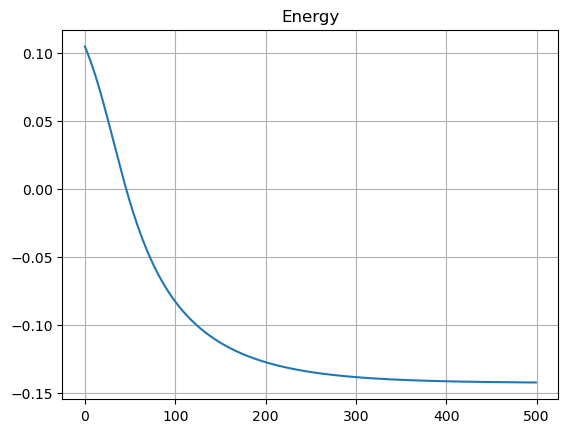

In [21]:
plt.plot(energies); plt.title('Energy'); plt.grid(); plt.show()

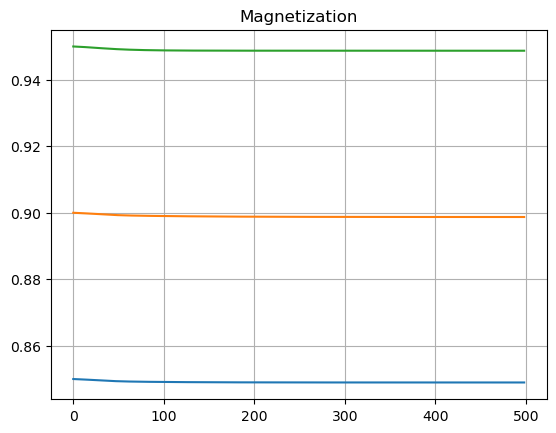

In [22]:
plt.plot(magnetizations); plt.title("Magnetization"); plt.grid(); plt.show()

In [23]:
evals = np.linalg.eigvalsh(
    H.to_matrix()
)

print("Exact spectrum")

print(np.round(evals,2))

Exact spectrum
[-0.2 -0.2 -0.2 -0.2 -0.2 -0.2  0.6  0.6]


In [24]:
def compute_betas_dense(psi, Hm, constraints):

    m = len(constraints)

    gamma = np.zeros(m)
    Gmat = np.zeros((m,m))

    Hpsi = Hm @ psi

    for i, Bi in enumerate(constraints):

        Bipsi = Bi @ psi

        gamma[i] = -np.real(
            np.vdot(Hpsi, Bipsi)
        )

        for j, Bj in enumerate(constraints):

            Gmat[i,j] = np.real(
                np.vdot(
                    Bipsi,
                    Bj @ psi
                )
            )

    return np.linalg.pinv(Gmat) @ gamma

In [25]:
Hm = H.to_matrix()

In [26]:
Cm = [Cj.to_matrix() for Cj in C]

I = np.eye(Hm.shape[0])

constraints_mat = [I]
constraints_mat.extend(Cm)

In [27]:
from scipy.sparse.linalg import expm_multiply

def cite_step(
    psi,
    Hm,
    constraints_mat,
    dt,
    nsub=100
):

    h = dt / nsub

    for _ in range(nsub):

        beta = compute_betas_dense(
            psi,
            Hm,
            constraints_mat
        )

        G = Hm.copy()

        for b, B in zip(beta, constraints_mat):
            G += b * B

        psi = expm_multiply(-h * G, psi)
        psi /= np.linalg.norm(psi)

    return psi

In [28]:
import numpy as np
from tqdm.notebook import tqdm

energies_exact = []
constraints_history = [[] for _ in Cm]

append_energy = energies_exact.append
append_constraints = [hist.append for hist in constraints_history]

psi_exact = psi.data

for step in tqdm(range(nsteps), desc="CITE"):

    psi_exact = cite_step(
        psi_exact,
        Hm,
        constraints_mat,
        dt=dt
    )

    append_energy(
        np.real(
            np.vdot(
                psi_exact,
                Hm @ psi_exact
            )
        )
    )

    for append, B in zip(append_constraints, constraints_mat):

        append(
            np.real(
                np.vdot(
                    psi_exact,
                    B @ psi_exact
                )
            )
        )

CITE:   0%|          | 0/500 [00:00<?, ?it/s]

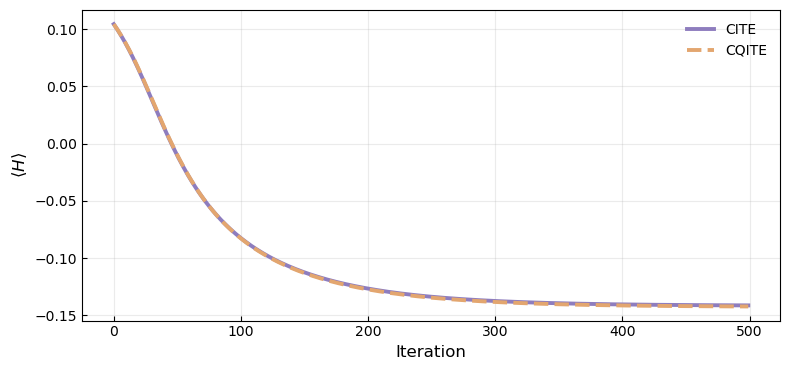

In [29]:
import numpy as np
import matplotlib.pyplot as plt

energies = np.asarray(energies)
energies_exact = np.asarray(energies_exact)

iters = np.arange(len(energies))

fig, ax = plt.subplots(
    figsize=(8, 3.8),
    dpi=100
)

# Muted purple and orange palette.
cite_color = "#8E7DBE"      # muted violet
cqite_color = "#E3A66F"     # soft orange

ax.plot(
    iters,
    energies_exact,
    lw=2.8,
    color=cite_color,
    label="CITE"
)

ax.plot(
    iters,
    energies,
    lw=2.8,
    ls="--",
    color=cqite_color,
    label="CQITE"
)

ax.set_xlabel("Iteration", fontsize=12)
ax.set_ylabel(r"$\langle H\rangle$", fontsize=12)

ax.grid(True, alpha=0.25)
ax.legend(frameon=False)

ax.tick_params(direction="in")

plt.tight_layout()
fig.savefig("zz_exp.pdf", bbox_inches="tight", transparent=True)

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

energies = np.asarray(energies)
energies_exact = np.asarray(energies_exact)

iters = np.arange(len(energies))

# ============================================================
# Colors
# ============================================================

cite_color = "#8E7DBE"      # muted violet
cqite_color = "#E3A66F"     # soft orange

# ============================================================
# Figure.
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 3.8),
    dpi=100
)

# Limits
ax.set_xlim(iters.min(), iters.max())

ymin = min(energies.min(), energies_exact.min())
ymax = max(energies.max(), energies_exact.max())

margin = 0.05 * (ymax - ymin)

ax.set_ylim(
    ymin - margin,
    ymax + margin
)

# ============================================================
# CITE: reference curve
# ============================================================

ax.plot(
    iters,
    energies_exact,
    lw=2.8,
    color=cite_color,
    label="CITE"
)

# ============================================================
# CQITE: future curve shown with transparency
# ============================================================

ax.plot(
    iters,
    energies,
    lw=2.8,
    ls="--",
    color=cqite_color,
    alpha=0.35
)

# ============================================================
# CQITE: portion of the trajectory traversed by the point.
# ============================================================

line_progress, = ax.plot(
    [],
    [],
    lw=2.8,
    ls="--",
    color=cqite_color,
    alpha=1.0,
    label="CQITE"
)

# ============================================================
# Animated point.
# ============================================================

point, = ax.plot(
    [],
    [],
    "o",
    color=cqite_color,
    markersize=9,
    markeredgecolor="white",
    markeredgewidth=1.2,
    zorder=10
)

# ============================================================
# Labels and style
# ============================================================

ax.set_xlabel("Iteration", fontsize=12)
ax.set_ylabel(r"$\langle H\rangle$", fontsize=12)

ax.grid(True, alpha=0.25)
ax.legend(frameon=False)

ax.tick_params(direction="in")

plt.tight_layout()

# ============================================================
# Animation
# ============================================================

# 100 frames distributed over the COMPLETE trajectory
frame_indices = np.linspace(
    0,
    len(iters) - 1,
    100,
    dtype=int
)

def update(i):

    # Already-traversed curve.
    line_progress.set_data(
        iters[:i + 1],
        energies[:i + 1]
    )

    # Point position.
    point.set_data(
        [iters[i]],
        [energies[i]]
    )

    return line_progress, point


anim = FuncAnimation(
    fig,
    update,
    frames=frame_indices,
    interval=1000 / 30,
    blit=True,
    repeat=True
)

# ============================================================
# Save GIF
# ============================================================

anim.save(
    "CQITE_evolution.gif",
    writer=PillowWriter(fps=20)
)

plt.close(fig)

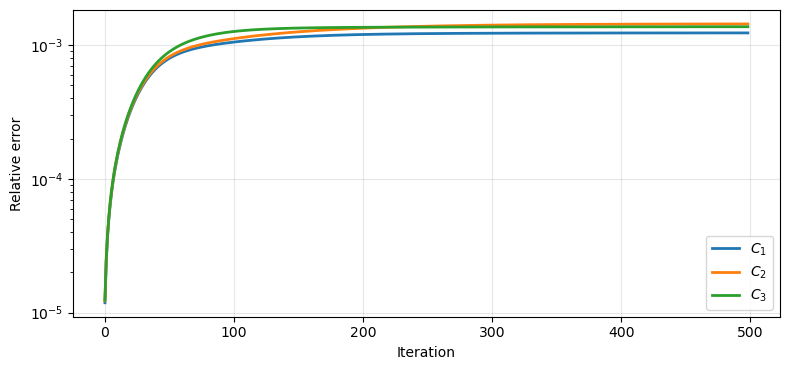

In [31]:
mag = np.asarray(magnetizations)

fig, ax = plt.subplots(
    figsize=(8, 3.8)
)

eps = 5e-3

for k in range(mag.shape[1]):

    rel_error = np.abs((mag[:, k] - target[k]) / target[k])

    ax.plot(
        rel_error * (1 + k * eps),
        lw=2,
        label=rf"$C_{k+1}$"
    )

ax.set_yscale("log")

ax.set_xlabel("Iteration")
ax.set_ylabel(r"Relative error")
ax.grid(alpha=.3)

ax.legend()

plt.tight_layout()

#fig.savefig("zz_con.pdf", bbox_inches="tight", transparent=True)

In [75]:
#mag = np.asarray(magnetizations)

#fig, ax = plt.subplots(
#    figsize=(8,3.8)
#)

#for k in range(mag.shape[1]):
#    ax.plot(
#        np.abs(mag[:,k]),
#        lw=2,
#        label=rf"$C_{k+1}$"
#    )

#ax.set_xlabel("Iteration")
#ax.set_ylabel(r"$\langle C\rangle$")
#ax.grid(alpha=.3)

#ax.legend()

#plt.tight_layout()

#fig.savefig("zz_mag.pdf", bbox_inches="tight", transparent=True)

In [77]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

mag = np.asarray(magnetizations)
target = np.asarray(target)

iters = np.arange(mag.shape[0])

# ============================================================
# Colors
# ============================================================

colors = [
    "#8E7DBE",   # C1 - violet
    "#E3A66F",   # C2 - orange
    "#6FA8A0"    # C3 - green
]

# ============================================================
# Figure
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 3.8),
    dpi=100
)

eps = 5e-3

# ============================================================
# Relative errors
# ============================================================

rel_errors = np.zeros_like(mag, dtype=float)

for k in range(mag.shape[1]):
    rel_errors[:, k] = (
        np.abs(
            (mag[:, k] - target[k]) / target[k]
        )
        * (1 + k * eps)
    )

# ============================================================
# Axis limits
# ============================================================

ax.set_xlim(-10, iters.max()+10)

ymin = max(rel_errors.min(), 1e-12)
ymax = rel_errors.max()

ax.set_ylim(ymin / 2, ymax * 2)
ax.set_yscale("log")

# ============================================================
# Future curves
# SAME COLORS, visibly transparent
# ============================================================

for k in range(mag.shape[1]):
    ax.plot(
        iters,
        rel_errors[:, k],
        lw=2,
        color=colors[k],
        alpha=0.35
    )

# ============================================================
# Progress curves
# SAME COLORS, fully opaque
# ============================================================

lines_progress = []

for k in range(mag.shape[1]):

    line, = ax.plot(
        [],
        [],
        lw=2.2,
        color=colors[k],
        alpha=1.0,
        label=rf"$C_{k+1}$"
    )

    lines_progress.append(line)

# ============================================================
# Animated points
# ============================================================

points = []

for k in range(mag.shape[1]):

    point, = ax.plot(
        [],
        [],
        "o",
        color=colors[k],
        markersize=9,
        markeredgecolor="white",
        markeredgewidth=1.2,
        zorder=10
    )

    points.append(point)

# ============================================================
# Labels and style
# ============================================================

ax.set_xlabel("Iteration", fontsize=12)
ax.set_ylabel("Relative error", fontsize=12)

ax.grid(True, alpha=0.25)

ax.legend(
    frameon=False,
    handlelength=2.0
)

ax.tick_params(direction="in")

plt.tight_layout()

# ============================================================
# Animation
# ============================================================

# 100 frames spanning the complete 500 iterations
frame_indices = np.linspace(
    0,
    len(iters) - 1,
    100,
    dtype=int
)

def update(i):

    for k in range(mag.shape[1]):

        # Already traversed: opaque
        lines_progress[k].set_data(
            iters[:i + 1],
            rel_errors[:i + 1, k]
        )

        # Current position
        points[k].set_data(
            [iters[i]],
            [rel_errors[i, k]]
        )

    return lines_progress + points


anim = FuncAnimation(
    fig,
    update,
    frames=frame_indices,
    interval=33,
    blit=True,
    repeat=True
)

# ============================================================
# Save GIF
# ============================================================

anim.save(
    "CQITE_magnetization_error_evolution.gif",
    writer=PillowWriter(fps=20)
)

plt.close(fig)


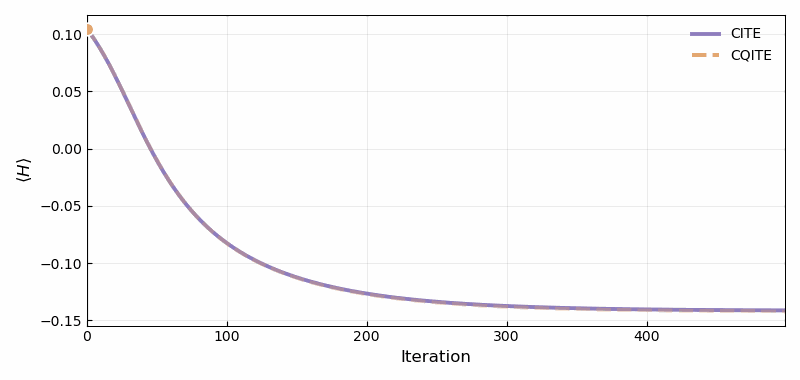
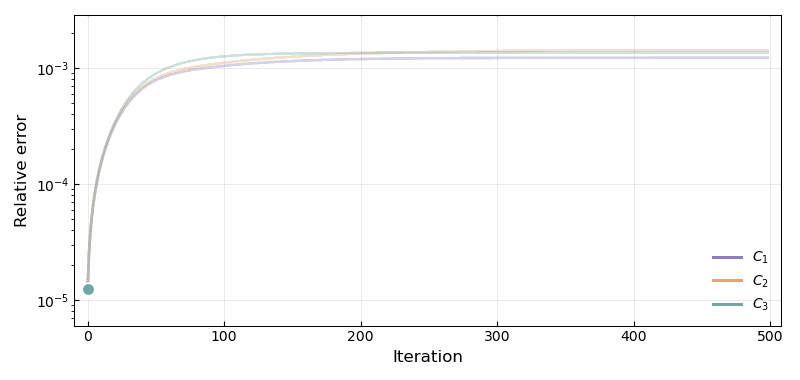

In [78]:
from IPython.display import HTML, display
import base64

def gif_to_base64(filename):
    with open(filename, "rb") as f:
        return base64.b64encode(f.read()).decode("ascii")

energy_gif = gif_to_base64("CQITE_evolution.gif")
mag_gif = gif_to_base64("CQITE_magnetization_error_evolution.gif")

display(HTML(f"""
<div style="
    display: flex;
    flex-direction: row;
    gap: 20px;
    align-items: flex-start;
    justify-content: center;
">
    <div style="width: 48%; text-align: center;">
        <img
            src="data:image/gif;base64,{energy_gif}"
            style="width: 100%; height: auto;"
        >
    </div>

    <div style="width: 48%; text-align: center;">
        <img
            src="data:image/gif;base64,{mag_gif}"
            style="width: 100%; height: auto;"
        >
    </div>
</div>
"""))